# Foundations 7: Calculus

*Learning path: foundations, part 7 of 9.* [Index](README.md) · Previous: [Complex numbers](06-complex-numbers.ipynb) · Next: [Differential equations](08-differential-equations.ipynb)

Calculus is the mathematics of change. It has two halves that turn out to be inverses of each other: the
**derivative** (how fast something changes) and the **integral** (how much has accumulated). You will learn

* limits, the idea behind everything else,
* the derivative as the slope of a tangent line, and the rules for computing it,
* how to find maxima and minima,
* the integral as an area, approximated by sums of rectangles,
* the fundamental theorem of calculus,
* Taylor polynomials: approximating a function by a polynomial.

## 1. Limits

What does $\dfrac{\sin x}{x}$ do as $x$ gets close to 0? At $x = 0$ itself it is $0/0$, meaningless. But we can look at
values close to 0. `table(expr, k, a, b)` computes the expression for $k = a, \ldots, b$; here $x = 10^{-k}$:

In [1]:
table(eval(sin(10^-k)/10^-k), k, 1, 6)

0.9983341664682815	0.9999833334166665	0.9999998333333416	0.9999999983333334	0.9999999999833333	0.9999999999998334

The values approach 1. We say the **limit** of $\sin(x)/x$ as $x \to 0$ is 1. `limit(f, x, a)` computes it exactly:

In [2]:
limit(sin(x)/x, x, 0)
limit((x^2 - 1)/(x - 1), x, 1)
limit((1 + 1/n)^n, n, inf)

1
2
e

The last one is how the number $e$ was discovered: by compounding interest more and more often (Bernoulli, 1683).

## 2. The derivative

The slope of the straight line through the points $(x, f(x))$ and $(x + h, f(x + h))$ on a graph is

$$\frac{f(x + h) - f(x)}{h}.$$

Such a line is a *secant*. As $h \to 0$ the two points merge and the secant becomes the **tangent**: the line that
touches the curve at $x$. Its slope is the **derivative** $f'(x)$. For $f(x) = x^2$:

In [3]:
f(x) := x^2;
limit((f(x + h) - f(x))/h, h, 0)

2*x

So the slope of $x^2$ at any point $x$ is $2x$. At $x = 1$ the slope is 2 and the tangent line is
$y = f(1) + f'(1)(x - 1) = 1 + 2(x - 1)$. The plot shows the curve, two secants through $(1, 1)$ with $h = 1$ and
$h = 0.5$, and the tangent. Their slopes are $(f(1+h) - f(1))/h = 2 + h$: 3, 2.5, and in the limit 2.

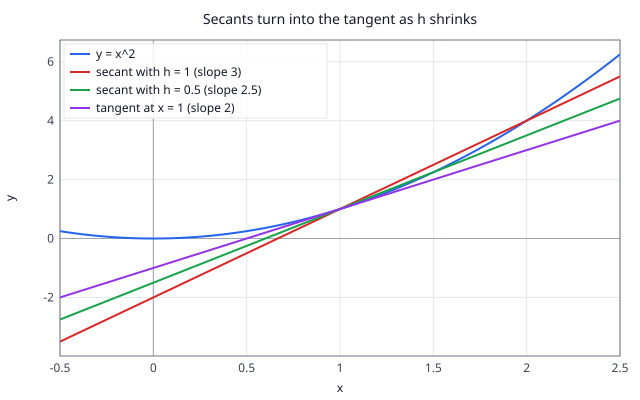

In [4]:
s1 = 1 + 3*(x - 1);
s2 = 1 + 2.5*(x - 1);
tangent = 1 + 2*(x - 1);
p = plot(f(x), s1, s2, tangent, x, -0.5, 2.5);
p = legend(p, "y = x^2", "secant with h = 1 (slope 3)", "secant with h = 0.5 (slope 2.5)", "tangent at x = 1 (slope 2)");
labels(title(p, "Secants turn into the tangent as h shrinks"), "x", "y")

### Rules

`deriv(f, x)` (or `f'(x)` for a function you defined) computes derivatives with the usual rules: the power rule
$(x^n)' = nx^{n-1}$, the product rule $(uv)' = u'v + uv'$, the chain rule $f(g(x))' = f'(g(x))\,g'(x)$:

In [5]:
deriv(x^5, x)
deriv(sin(x)*exp(x), x)
deriv(sin(x^2), x)
deriv(log(x), x)
f'(x)

5*x^4

exp(x)*sin(x)+exp(x)*cos(x)

2*x*cos(x^2)

1/x

2*x

## 3. Maxima and minima

At the top of a hill or the bottom of a valley the tangent is horizontal: $f'(x) = 0$. That is how calculus solves
optimization problems.

**Problem:** a can (a cylinder) must hold 1 litre $= 1000\,\text{cm}^3$. Which radius $r$ uses the least metal? The
height $h$ follows from the volume $\pi r^2 h = 1000$, and the area of metal is the two lids plus the side:

In [6]:
h = 1000/(pi*r^2);
A(r) := 2*pi*r^2 + 2*pi*r*h;
A(r)
solve(A'(r) == 0, r)
eval(ans)

2*pi*r^2+2000/r

5.41926070139289	-2.709630350696445-4.6932174371369175*i	-2.709630350696445+4.6932174371369175*i

5.41926070139289	-2.709630350696445-4.6932174371369175*i	-2.709630350696445+4.6932174371369175*i

The best radius is $r = \sqrt[3]{500/\pi} \approx 5.42\,\text{cm}$. Then $h = 1000/(\pi r^2) \approx 10.8$: the
height equals the diameter. The plot confirms that the area is smallest there. The horizontal axis is the radius in
cm, the vertical axis the area of metal in cm²:

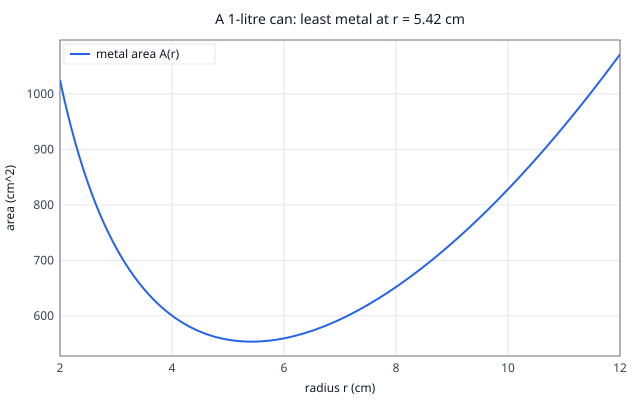

In [7]:
labels(title(legend(plot(A(r), r, 2, 12), "metal area A(r)"), "A 1-litre can: least metal at r = 5.42 cm"), "radius r (cm)", "area (cm^2)")
clear

Real cans are taller than that: the lids are made of thicker metal, which changes the optimum.

## 4. The integral

The area under the graph of $f(x) = x^2$ between $x = 0$ and $x = 1$ is not a rectangle or a triangle. Archimedes'
idea: cut it into thin strips and add up the rectangles. With $n$ strips of width $1/n$, the rectangle over the $k$-th
strip has height $f(k/n)$:

$$\text{area} \approx \sum_{k=0}^{n-1} f\!\left(\tfrac{k}{n}\right)\cdot \tfrac1n.$$

`sum(expr, k, a, b)` adds the expression for $k = a, \ldots, b$. We make the sum a function of $n$ and try more and
more strips:

In [8]:
f(x) := x^2;
area(n) := sum(f(k/n)/n, k, 0, n - 1);
area(10)
eval(area(100))
eval(area(1000))

57/200

0.32835
0.3328335

The sums approach $1/3$. With a symbolic $n$ Galileo even finds the formula for the sum, and its limit as
$n \to \infty$:

In [9]:
S = sum(f(k/n)/n, k, 0, n - 1)
limit(S, n, inf)

(n-1)*(2*(n-1)^2+3*(n-1)+1)/(6*n^3)

1/3

The limit is the **integral** $\int_0^1 x^2\,dx = 1/3$. `integrate(f, x, a, b)` computes it directly:

In [10]:
integrate(x^2, x, 0, 1)
integrate(sin(x), x, 0, pi)
integrate(exp(-x^2), x, -inf, inf)

1/3

2
1.7724538509055159

The last one has no elementary antiderivative, so Galileo computes it numerically: $1.7725 = \sqrt\pi$, the famous
Gaussian integral behind the bell curve.

## 5. The fundamental theorem

Differentiation and integration undo each other: if $F'(x) = f(x)$ then

$$\int_a^b f(x)\,dx = F(b) - F(a).$$

$F$ is an **antiderivative** of $f$. `integrate(f, x)` (without limits) finds one:

In [11]:
F = integrate(x^2, x)
subs(F, x, 1) - subs(F, x, 0)
deriv(F, x)
integrate(x*exp(x), x)
deriv(integrate(x*exp(x), x), x)

x^3/3

1/3

x^2

exp(x)*(x-1)

exp(x)*(x-1)+exp(x)

### Area between two curves

The area between $y = x + 2$ (above) and $y = x^2$ (below) from one crossing point to the other is the integral of
the difference. The crossing points come from `solve`:

In [12]:
solve(x^2 == x + 2, x)
integrate((x + 2) - x^2, x, -1, 2)

-1	2

9/2

## 6. Taylor polynomials

Near a point, a smooth function looks like a polynomial. The **Taylor polynomial** of degree $n$ around 0 matches the
value and the first $n$ derivatives at 0:

$$f(x) \approx f(0) + f'(0)\,x + \frac{f''(0)}{2!}x^2 + \cdots + \frac{f^{(n)}(0)}{n!}x^n.$$

`taylor(f, x, a, n)` computes it around $x = a$:

In [13]:
taylor(exp(x), x, 0, 5)
taylor(sin(x), x, 0, 7)
taylor(cos(x), x, 0, 6)

x^5/120+x^4/24+x^3/6+x^2/2+x+1

x^5/120-x^7/5040-x^3/6+x

x^4/24-x^6/720-x^2/2+1

The more terms, the further from 0 the approximation stays good. The plot compares $\sin x$ (blue) with its Taylor
polynomials of degree 1, 3 and 7 for $x$ from $-2\pi$ to $2\pi$:

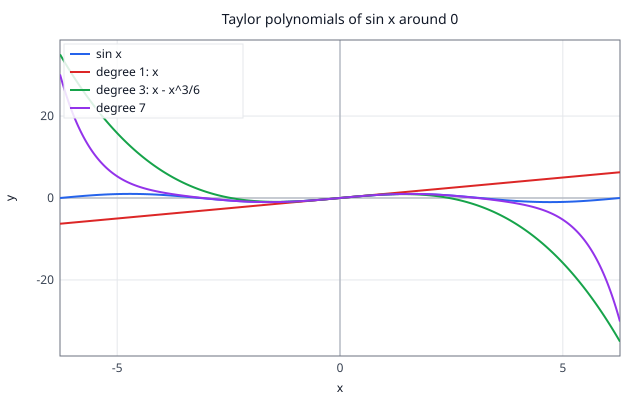

In [14]:
p = plot(sin(x), taylor(sin(x), x, 0, 1), taylor(sin(x), x, 0, 3), taylor(sin(x), x, 0, 7), x, -2*pi, 2*pi);
p = legend(p, "sin x", "degree 1: x", "degree 3: x - x^3/6", "degree 7");
labels(title(p, "Taylor polynomials of sin x around 0"), "x", "y")

Putting $x = 1$ in the series of $e^x$ gives a fast way to compute $e = \sum 1/k!$:

In [15]:
eval(sum(1/factorial(k), k, 0, 15))
eval(e)

2.7182818284589945
2.718281828459045

## Summary

* `limit(f, x, a)`: what $f$ approaches; `inf` for infinity.
* The derivative is the limit of secant slopes; `deriv(f, x)` and `f'(x)`. Maxima and minima: solve $f'(x) = 0$.
* The integral is the limit of sums of rectangles; `integrate(f, x, a, b)`, and `integrate(f, x)` for antiderivatives.
* Fundamental theorem: $\int_a^b f = F(b) - F(a)$ where $F' = f$.
* `taylor(f, x, a, n)` approximates $f$ by a polynomial.

**Try it:** a rectangle has perimeter 20; which sides give the largest area? Find the area enclosed by $y = \sin x$
and the $x$-axis between 0 and $2\pi$ (careful with the sign!).

Next: [Differential equations](08-differential-equations.ipynb), where the unknown is a whole function.

## Sources

1. I. Newton, *Method of Fluxions* (written 1671, published 1736); G. W. Leibniz, "Nova methodus pro maximis et minimis", *Acta Eruditorum* (1684).
2. J. Bernoulli, *Quæstiones nonnullæ de usuris* (1690). Continuous compounding and the number $e$.
3. M. Spivak, *Calculus*, 4th ed., Publish or Perish (2008).